In [2]:
from google.colab import files
uploaded = files.upload()

ModuleNotFoundError: No module named 'google.colab'

In [1]:
import pandas as pd

df = pd.read_csv("ai-impact-jobs-layoff-risk-dataset.csv")
df.head()

,Age,Education_Level,Years_of_Experience,Industry,Job_Role,Company_Size,Job_Level,Routine_Task_Percentage,Creativity_Requirement,Human_Interaction_Level,AI_Adoption_Level,Number_of_AI_Tools_Used,AI_Usage_Hours_Per_Week,Tasks_Automated_Percentage,AI_Training_Hours,Layoff_Risk
0,59,Master's,6,Finance,Accountant,Medium,Entry,84,21,94,Medium,5,7,40,26,High
1,44,Master's,14,Manufacturing,Production Supervisor,Small,Entry,30,84,68,Low,2,2,14,9,Low
2,36,Bachelor's,7,Retail,Store Manager,Medium,Senior,12,86,71,Low,0,1,6,3,Low
3,27,Bachelor's,6,Finance,Auditor,Large,Entry,90,18,21,Medium,3,10,67,26,High
4,49,High School,12,Finance,Auditor,Small,Entry,49,52,72,Medium,5,13,26,19,Medium


df.shape

In [47]:
df.shape

(20000, 16)

In [48]:
df.groupby("Layoff_Risk")["Routine_Task_Percentage"].mean()

Layoff_Risk
High      75.172870
Low       28.540139
Medium    51.255567
Name: Routine_Task_Percentage, dtype: float64

In [49]:
df.groupby("Layoff_Risk")["Creativity_Requirement"].mean()

Layoff_Risk
High      23.844343
Low       71.926840
Medium    48.296167
Name: Creativity_Requirement, dtype: float64

df.groupby("Layoff_Risk")["AI_Adoption_Level"].value_counts()

In [50]:
df.groupby("Layoff_Risk")["AI_Adoption_Level"].value_counts()

Layoff_Risk  AI_Adoption_Level
High         Medium               4680
             High                 1143
             Low                   974
Low          Low                  5919
             Medium                666
             High                   17
Medium       Low                  3646
             Medium               2700
             High                  255
Name: count, dtype: int64

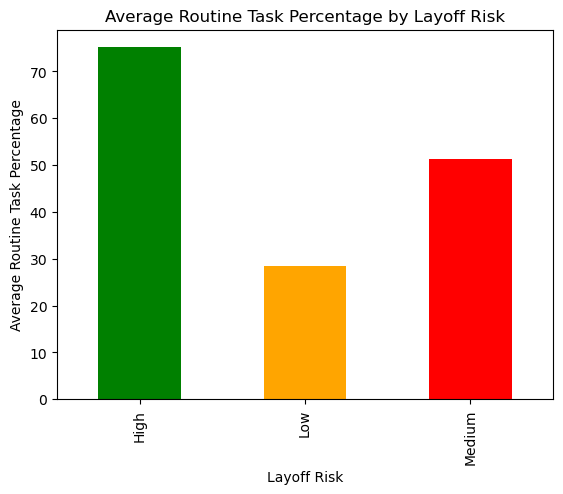

In [51]:
import matplotlib.pyplot as plt
avg_routine = df.groupby("Layoff_Risk")["Routine_Task_Percentage"].mean()

avg_routine.plot(kind="bar", color=["green", "orange", "red"])
plt.title("Average Routine Task Percentage by Layoff Risk")
plt.xlabel("Layoff Risk")
plt.ylabel("Average Routine Task Percentage")
plt.show()

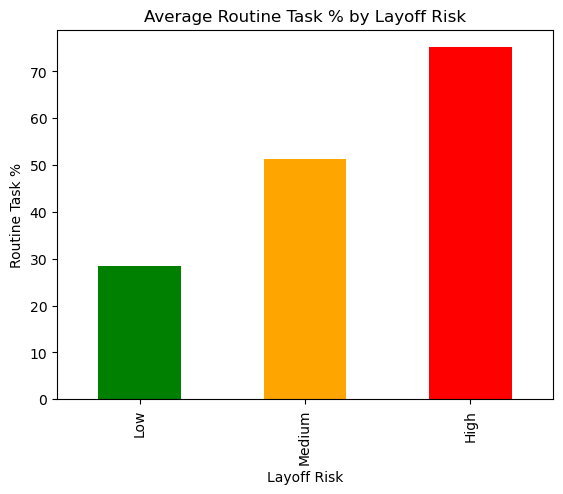

In [52]:
risk_order = ["Low", "Medium", "High"]
avg_routine = avg_routine.reindex(risk_order)

avg_routine.plot(kind="bar", color=["green", "orange", "red"])
plt.title("Average Routine Task % by Layoff Risk")
plt.xlabel("Layoff Risk")
plt.ylabel("Routine Task %")
plt.show()

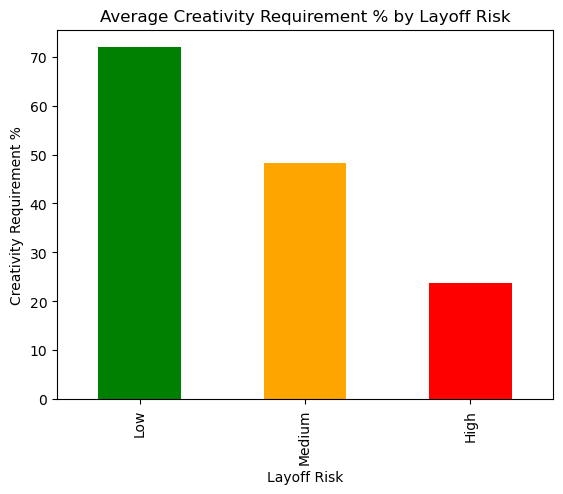

In [53]:
avg_creativity = df.groupby("Layoff_Risk")["Creativity_Requirement"].mean()
risk_order = ["Low", "Medium", "High"]
avg_creativity = avg_creativity.reindex(risk_order)

avg_creativity.plot(kind="bar", color=["green", "orange", "red"])
plt.title("Average Creativity Requirement % by Layoff Risk")
plt.xlabel("Layoff Risk")
plt.ylabel("Creativity Requirement %")
plt.show()

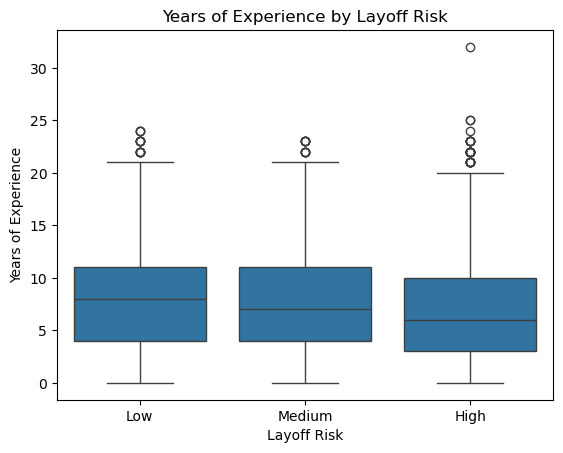

In [54]:
import seaborn as sns

sns.boxplot(data=df, x="Layoff_Risk", y="Years_of_Experience", order=risk_order)
plt.title("Years of Experience by Layoff Risk")
plt.xlabel("Layoff Risk")
plt.ylabel("Years of Experience")
plt.show()


In [55]:
df = pd.read_csv("ai-impact-jobs-layoff-risk-dataset.csv")

In [56]:
df["Education_Level"].unique()

array(["Master's", "Bachelor's", 'High School', 'PhD'], dtype=object)

In [57]:
df["Job_Level"].unique()

array(['Entry', 'Senior', 'Mid'], dtype=object)

In [58]:
education_map = {"High School": 0, "Bachelor's": 1, "Master's": 2, "PhD": 3}
df["Education_Level"] = df["Education_Level"].map(education_map)

In [59]:
df['Education_Level'].unique()

array([2, 1, 0, 3])

In [60]:
size_map = {"Small": 0, "Medium": 1, "Large": 2}
df["Company_Size"] = df["Company_Size"].map(size_map)

In [61]:
df["Company_Size"].unique()

array([1, 0, 2])

In [62]:
level_map = {"Entry": 0, "Mid":1, "Senior":2}
df["Job_Level"] = df["Job_Level"].map(level_map)

In [63]:
df["Job_Level"].unique()

array([0, 2, 1])

In [64]:
ai_map = {"Low": 0, "Medium": 1, "High": 2}
df["AI_Adoption_Level"] = df["AI_Adoption_Level"].map(ai_map)
df["AI_Adoption_Level"].unique()

array([1, 0, 2])

In [65]:
df = pd.get_dummies(df, columns=["Industry", "Job_Role"])

In [66]:
df.head()

,Age,Education_Level,Years_of_Experience,Company_Size,Job_Level,Routine_Task_Percentage,Creativity_Requirement,Human_Interaction_Level,AI_Adoption_Level,Number_of_AI_Tools_Used,...,Job_Role_Production Supervisor,Job_Role_Quality Engineer,Job_Role_Research Assistant,Job_Role_Sales Associate,Job_Role_Software Engineer,Job_Role_Store Manager,Job_Role_Supply Chain Analyst,Job_Role_Support Specialist,Job_Role_Teacher,Job_Role_Warehouse Manager
0,59,2,6,1,0,84,21,94,1,5,...,False,False,False,False,False,False,False,False,False,False
1,44,2,14,0,0,30,84,68,0,2,...,True,False,False,False,False,False,False,False,False,False
2,36,1,7,1,2,12,86,71,0,0,...,False,False,False,False,False,True,False,False,False,False
3,27,1,6,2,0,90,18,21,1,3,...,False,False,False,False,False,False,False,False,False,False
4,49,0,12,0,0,49,52,72,1,5,...,False,False,False,False,False,False,False,False,False,False


In [67]:
df.shape

(20000, 46)

In [68]:
ai_map = {"Low": 0, "Medium": 1, "High": 2}
df["Layoff_Risk"] = df["Layoff_Risk"].map(ai_map)
df["Layoff_Risk"].unique()

array([2, 0, 1])

In [69]:
df.head()

,Age,Education_Level,Years_of_Experience,Company_Size,Job_Level,Routine_Task_Percentage,Creativity_Requirement,Human_Interaction_Level,AI_Adoption_Level,Number_of_AI_Tools_Used,...,Job_Role_Production Supervisor,Job_Role_Quality Engineer,Job_Role_Research Assistant,Job_Role_Sales Associate,Job_Role_Software Engineer,Job_Role_Store Manager,Job_Role_Supply Chain Analyst,Job_Role_Support Specialist,Job_Role_Teacher,Job_Role_Warehouse Manager
0,59,2,6,1,0,84,21,94,1,5,...,False,False,False,False,False,False,False,False,False,False
1,44,2,14,0,0,30,84,68,0,2,...,True,False,False,False,False,False,False,False,False,False
2,36,1,7,1,2,12,86,71,0,0,...,False,False,False,False,False,True,False,False,False,False
3,27,1,6,2,0,90,18,21,1,3,...,False,False,False,False,False,False,False,False,False,False
4,49,0,12,0,0,49,52,72,1,5,...,False,False,False,False,False,False,False,False,False,False


In [70]:
X = df.drop("Layoff_Risk", axis=1)
y = df["Layoff_Risk"]

In [71]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [72]:
print(X_train.shape)
print(X_test.shape)

(16000, 45)
(4000, 45)


In [73]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [74]:
y_pred = model.predict(X_test)

In [75]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.94      0.93      0.93      1296
           1       0.85      0.85      0.85      1329
           2       0.91      0.92      0.92      1375

    accuracy                           0.90      4000
   macro avg       0.90      0.90      0.90      4000
weighted avg       0.90      0.90      0.90      4000



In [76]:
model = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_split=5,
    random_state=42)
model.fit(X_train, y_train)

,n_estimators,200
,criterion,'gini'
,max_depth,15
,min_samples_split,5
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [77]:
y_pred = model.predict(X_test)

from sklearn.metrics import accuracy_score, classification_report

print(accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

0.889
              precision    recall  f1-score   support

           0       0.94      0.91      0.93      1296
           1       0.83      0.84      0.83      1329
           2       0.90      0.91      0.91      1375

    accuracy                           0.89      4000
   macro avg       0.89      0.89      0.89      4000
weighted avg       0.89      0.89      0.89      4000



In [78]:
model = RandomForestClassifier(
    n_estimators=300,
    random_state=42
)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print(accuracy_score(y_test, y_pred))

0.90025


In [79]:
import joblib

joblib.dump(model, "layoff_risk_model.pkl")

['layoff_risk_model.pkl']

## Model evaluation

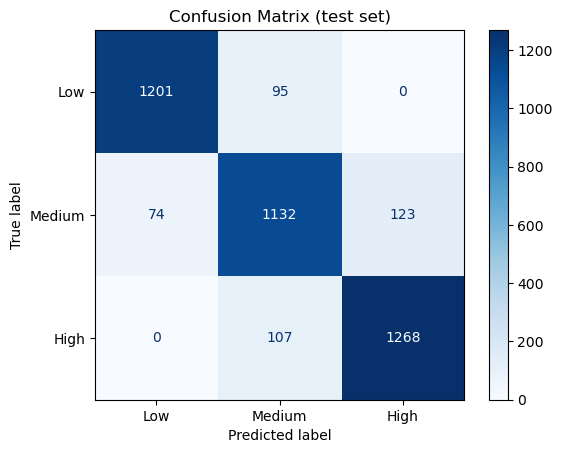

In [80]:
# Confusion matrix: where does the model get confused?
from sklearn.metrics import ConfusionMatrixDisplay

y_pred = model.predict(X_test)
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Low", "Medium", "High"], cmap="Blues")
plt.title("Confusion Matrix (test set)")
plt.show()

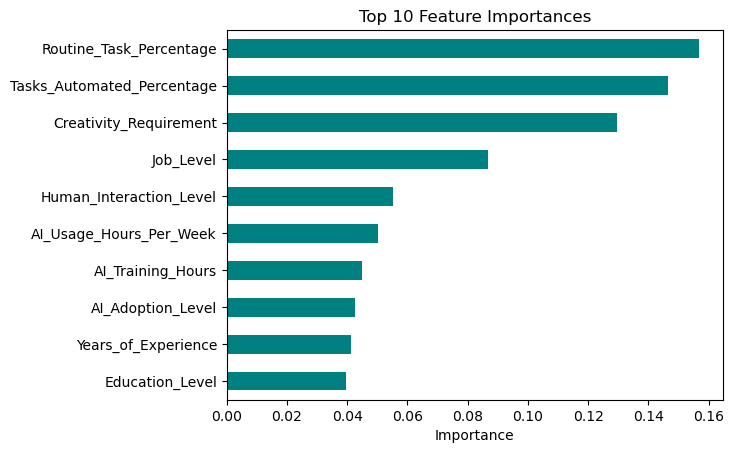

Routine_Task_Percentage       0.157
Tasks_Automated_Percentage    0.147
Creativity_Requirement        0.130
Job_Level                     0.087
Human_Interaction_Level       0.055
AI_Usage_Hours_Per_Week       0.050
AI_Training_Hours             0.045
AI_Adoption_Level             0.043
Years_of_Experience           0.041
Education_Level               0.039
dtype: float64


In [81]:
# Feature importance: which inputs drive the prediction most?
importances = pd.Series(model.feature_importances_, index=X_train.columns).sort_values()
importances.tail(10).plot(kind="barh", color="teal")
plt.title("Top 10 Feature Importances")
plt.xlabel("Importance")
plt.show()

print(importances.tail(10).sort_values(ascending=False).round(3))

In [82]:
# Compare with a simple baseline using 5-fold cross-validation
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Random Forest (300 trees)": model,
}
for name, m in models.items():
    scores = cross_val_score(m, X, y, cv=5)
    print(f"{name}: {scores.mean():.3f} (+/- {scores.std():.3f})")

Logistic Regression: 0.929 (+/- 0.004)
Random Forest (300 trees): 0.898 (+/- 0.003)


In [83]:
!pip install gradio

In [84]:
X_train.columns.tolist()

['Age',
 'Education_Level',
 'Years_of_Experience',
 'Company_Size',
 'Job_Level',
 'Routine_Task_Percentage',
 'Creativity_Requirement',
 'Human_Interaction_Level',
 'AI_Adoption_Level',
 'Number_of_AI_Tools_Used',
 'AI_Usage_Hours_Per_Week',
 'Tasks_Automated_Percentage',
 'AI_Training_Hours',
 'Industry_Education',
 'Industry_Finance',
 'Industry_Healthcare',
 'Industry_IT',
 'Industry_Logistics',
 'Industry_Manufacturing',
 'Industry_Retail',
 'Industry_Telecom',
 'Job_Role_Academic Coordinator',
 'Job_Role_Accountant',
 'Job_Role_Auditor',
 'Job_Role_Data Analyst',
 'Job_Role_Dispatcher',
 'Job_Role_Financial Analyst',
 'Job_Role_Health Analyst',
 'Job_Role_Inventory Analyst',
 'Job_Role_ML Engineer',
 'Job_Role_Medical Assistant',
 'Job_Role_Network Engineer',
 'Job_Role_Nurse',
 'Job_Role_Operations Analyst',
 'Job_Role_Operator',
 'Job_Role_Production Supervisor',
 'Job_Role_Quality Engineer',
 'Job_Role_Research Assistant',
 'Job_Role_Sales Associate',
 'Job_Role_Software Engi

In [85]:
education_map = {"High School": 0, "Bachelor's": 1, "Master's": 2, "PhD": 3}
size_map = {"Small": 0, "Medium": 1, "Large": 2}
level_map = {"Entry": 0, "Mid": 1, "Senior": 2}
ai_map = {"Low": 0, "Medium": 1, "High": 2}

industries = ["Education", "Finance", "Healthcare", "IT", "Logistics", "Manufacturing", "Retail", "Telecom"]
job_roles = ["Academic Coordinator", "Accountant", "Auditor", "Data Analyst", "Dispatcher",
             "Financial Analyst", "Health Analyst", "Inventory Analyst", "ML Engineer",
             "Medical Assistant", "Network Engineer", "Nurse", "Operations Analyst", "Operator",
             "Production Supervisor", "Quality Engineer", "Research Assistant", "Sales Associate",
             "Software Engineer", "Store Manager", "Supply Chain Analyst", "Support Specialist",
             "Teacher", "Warehouse Manager"]

In [86]:
defaults = X_train.mean().to_dict()
print(defaults)

{'Age': 40.3254375, 'Education_Level': 1.1985, 'Years_of_Experience': 7.268125, 'Company_Size': 0.94625, 'Job_Level': 0.70075, 'Routine_Task_Percentage': 51.865625, 'Creativity_Requirement': 47.794375, 'Human_Interaction_Level': 60.10475, 'AI_Adoption_Level': 0.5441875, 'Number_of_AI_Tools_Used': 2.4570625, 'AI_Usage_Hours_Per_Week': 6.77775, 'Tasks_Automated_Percentage': 37.1818125, 'AI_Training_Hours': 12.61475, 'Industry_Education': 0.125875, 'Industry_Finance': 0.1258125, 'Industry_Healthcare': 0.1248125, 'Industry_IT': 0.1256875, 'Industry_Logistics': 0.1226875, 'Industry_Manufacturing': 0.1214375, 'Industry_Retail': 0.1231875, 'Industry_Telecom': 0.1305, 'Job_Role_Academic Coordinator': 0.0420625, 'Job_Role_Accountant': 0.0405, 'Job_Role_Auditor': 0.0414375, 'Job_Role_Data Analyst': 0.044125, 'Job_Role_Dispatcher': 0.03875, 'Job_Role_Financial Analyst': 0.043875, 'Job_Role_Health Analyst': 0.0383125, 'Job_Role_Inventory Analyst': 0.0431875, 'Job_Role_ML Engineer': 0.040375, 'Job_

In [87]:
hidden_defaults = {
    "Years_of_Experience": 7.27,
    "Company_Size": 0.95,
    "Job_Level": 0.70,
    "Human_Interaction_Level": 60.10,
    "Number_of_AI_Tools_Used": 2.46,
    "AI_Usage_Hours_Per_Week": 6.78,
    "Tasks_Automated_Percentage": 37.18,
    "AI_Training_Hours": 12.61,
}

def predict_risk(age, education, industry, job_role, routine_task, creativity, ai_adoption):

    row = {col: 0 for col in X_train.columns}

    # Fill in hidden fields with realistic averages
    for col, val in hidden_defaults.items():
        row[col] = val

    # Fill in the 7 visible, user-controlled fields
    row["Age"] = age
    row["Education_Level"] = education_map[education]
    row["Routine_Task_Percentage"] = routine_task
    row["Creativity_Requirement"] = creativity
    row["AI_Adoption_Level"] = ai_map[ai_adoption]

    row[f"Industry_{industry}"] = True
    row[f"Job_Role_{job_role}"] = True

    input_df = pd.DataFrame([row])[X_train.columns]
    prediction = model.predict(input_df)[0]

    risk_labels = {0: "Low", 1: "Medium", 2: "High"}
    return f"Predicted Layoff Risk: {risk_labels[prediction]}"

In [88]:
import gradio as gr

ModuleNotFoundError: No module named 'gradio'

In [ ]:
import gradio as gr

demo = gr.Interface(
    fn=predict_risk,
    inputs=[
        gr.Slider(18, 65, value=30, label="Age"),
        gr.Dropdown(["High School", "Bachelor's", "Master's", "PhD"], label="Education Level"),
        gr.Dropdown(industries, label="Industry"),
        gr.Dropdown(job_roles, label="Job Role"),
        gr.Slider(0, 100, value=50, label="Routine Task % (how repetitive is the job)"),
        gr.Slider(0, 100, value=50, label="Creativity Requirement %"),
        gr.Dropdown(["Low", "Medium", "High"], label="AI Adoption Level"),
    ],
    outputs="text",
    title="AI Job Risk Analyzer",
    description="Enter a job profile to predict its risk of AI-driven layoff."
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://74337dea7e02c7a213.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Error: Failed to create kernel session on nbctl: nbctl vsessions unavailable: request to http://localhost:8888/api/internal/vsessions failed, reason: 

In [ ]:
import gradio as gr

# Proper font loading — Gradio's own GoogleFont class injects it correctly,
# instead of an @import that gets stripped/overridden
theme = gr.themes.Base(
    font=[gr.themes.GoogleFont("Space Grotesk"), gr.themes.GoogleFont("Inter"), "sans-serif"],
    font_mono=[gr.themes.GoogleFont("JetBrains Mono"), "monospace"],
).set(
    # ...keep everything else exactly the same as before...
    body_background_fill="#0a0e17", body_background_fill_dark="#0a0e17",
    background_fill_primary="#111827", background_fill_secondary="#0a0e17",
    border_color_primary="#1f2937", block_background_fill="#111827",
    block_border_color="#1f2937", block_label_text_color="#94a3b8",
    block_title_text_color="#f1f5f9", body_text_color="#e2e8f0",
    input_background_fill="#0a0e17", input_border_color="#1f2937",
    slider_color="#22d3ee",
    button_primary_background_fill="#22d3ee",
    button_primary_background_fill_hover="#06b6d4",
    button_primary_text_color="#0a0e17",
)

custom_css = """
#header h1 { font-weight: 700 !important; letter-spacing: -0.5px; }
#header p { color: #64748b !important; }
#scan-btn { font-weight: 700 !important; letter-spacing: 0.5px; }
#result-panel { padding: 28px !important; }

/* Reset Gradio's own span styling from leaking into our custom HTML */
#result-panel span {
    background: none !important;
    border: none !important;
    padding: 0 !important;
    border-radius: 0 !important;
    text-decoration: none !important;
    display: inline !important;
}
"""

Error: Failed to create kernel session on nbctl: nbctl vsessions unavailable: request to http://localhost:8888/api/internal/vsessions failed, reason: 

In [ ]:
def predict_risk(age, education, industry, job_role, routine_task, creativity, ai_adoption):
    row = {col: 0 for col in X_train.columns}
    for col, val in hidden_defaults.items():
        row[col] = val
    row["Age"] = age
    row["Education_Level"] = education_map[education]
    row["Routine_Task_Percentage"] = routine_task
    row["Creativity_Requirement"] = creativity
    row["AI_Adoption_Level"] = ai_map[ai_adoption]
    row[f"Industry_{industry}"] = True
    row[f"Job_Role_{job_role}"] = True
    input_df = pd.DataFrame([row])[X_train.columns]
    prediction = model.predict(input_df)[0]
    probs = model.predict_proba(input_df)[0]  # NEW: confidence per class

    risk_config = {
        0: {"label": "LOW",    "color": "#34d399", "pct": 20, "msg": "This role shows strong resistance to AI automation — it leans on skills AI still struggles to replicate."},
        1: {"label": "MEDIUM", "color": "#fbbf24", "pct": 55, "msg": "This role sits in the middle ground — part of the work could plausibly be automated over time."},
        2: {"label": "HIGH",   "color": "#f87171", "pct": 88, "msg": "This role has heavy overlap with tasks AI already automates well today."},
    }
    r = risk_config[prediction]

    html = f"""
    <div style="font-family:'Space Grotesk',sans-serif;">
      <div style="font-family:'JetBrains Mono',monospace; color:#64748b; font-size:0.78rem; letter-spacing:1px; margin-bottom:8px;">
        SCAN RESULT
      </div>
      <div style="font-size:2.6rem; font-weight:700; color:{r['color']}; text-shadow:0 0 24px {r['color']}66; margin-bottom:20px;">
        {r['label']} RISK
      </div>
      <div style="background:#0a0e17; border-radius:8px; height:10px; width:100%; overflow:hidden; margin-bottom:8px;">
        <div style="background:{r['color']}; box-shadow:0 0 12px {r['color']}; height:100%; width:{r['pct']}%;"></div>
      </div>
      <div style="display:flex; justify-content:space-between; font-family:'JetBrains Mono',monospace; font-size:0.7rem; color:#475569; margin-bottom:24px;">
        <span>LOW</span><span>MEDIUM</span><span>HIGH</span>
      </div>
      <div style="font-family:'Inter',sans-serif; color:#94a3b8; font-size:0.9rem; line-height:1.55; margin-bottom:26px;">
        {r['msg']}
      </div>
      <div style="border-top:1px solid #1f2937; padding-top:18px;">
        <div style="font-family:'JetBrains Mono',monospace; color:#475569; font-size:0.7rem; letter-spacing:1px; margin-bottom:10px;">
          MODEL CONFIDENCE
        </div>
        {"".join([f'''
        <div style="display:flex; align-items:center; gap:10px; margin-bottom:8px;">
          <span style="font-family:'JetBrains Mono',monospace; font-size:0.72rem; color:#64748b; width:60px;">{lbl}</span>
          <div style="flex:1; background:#0a0e17; border-radius:6px; height:6px; overflow:hidden;">
            <div style="background:{col}; height:100%; width:{p*100:.0f}%;"></div>
          </div>
          <span style="font-family:'JetBrains Mono',monospace; font-size:0.72rem; color:#64748b; width:34px; text-align:right;">{p*100:.0f}%</span>
        </div>
        ''' for lbl, col, p in zip(["LOW","MEDIUM","HIGH"], ["#34d399","#fbbf24","#f87171"], probs)])}
      </div>
    </div>
    """
    return html

with gr.Blocks(css=custom_css, theme=theme) as demo:
    with gr.Column(elem_id="header"):
        gr.Markdown("# AI Job Risk Analyzer")
        gr.Markdown("Enter a job profile below to scan its exposure to AI-driven automation.")

    with gr.Row():
        with gr.Column(scale=1):
            age = gr.Number(value=30, label="Age", precision=0)
            education = gr.Dropdown(["High School", "Bachelor's", "Master's", "PhD"], value="Bachelor's", label="Education Level")
            industry = gr.Dropdown(industries, value="IT", label="Industry")
            job_role = gr.Dropdown(job_roles, value="Software Engineer", label="Job Role")
            routine_task = gr.Slider(0, 100, value=50, step=1, label="Routine Task %")
            creativity = gr.Slider(0, 100, value=50, step=1, label="Creativity Requirement %")
            ai_adoption = gr.Dropdown(["Low", "Medium", "High"], value="Medium", label="AI Adoption Level")
            btn = gr.Button("Run Scan", elem_id="scan-btn", variant="primary")

        with gr.Column(scale=1, elem_id="result-panel"):
            output = gr.HTML("<div style='color:#475569; font-family:Inter; padding:40px 0;'>Fill in the form and hit <b>Run Scan</b> to see the result.</div>")

    btn.click(fn=predict_risk,
              inputs=[age, education, industry, job_role, routine_task, creativity, ai_adoption],
              outputs=output)

demo.launch()

import pandas as pd
pd.Series(model.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(10)


NameError: name 'gr' is not defined